# Explore RGC integrations

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import scanpy as sc
import rapids_singlecell as rsc

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from scatlastb_utils.io import read_anndata

/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/hpc/scratch/project.hca_integration/miniforge3/envs/rapids_singlecell/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. S

In [2]:
def clean_prefixes(adata, prefix):
    adata.obs.columns = adata.obs.columns.str.replace(prefix, '')
    
    adata.obsm = {
        key.replace(prefix, ''): adata.obsm[key]
        for key in adata.obsm.keys()
    }
    
    adata.obsp = {
        key.replace(prefix, ''): adata.obsp[key]
        for key in adata.obsp.keys()
    }
    
    adata.uns = {
        key.replace(prefix, ''): adata.uns[key]
        for key in adata.uns.keys()
    }

In [21]:
colors = [
    # 'cell_type',
    'ann_finest_level',
    'majority_consensus_disagreement',
    'scrublet_score',
    'qc_status',
    'sex',
    'age',
]

In [19]:
integrations = [
    'drvi--strategy=lineage--batch=None--n_hvgs=3000',
    'scvi--strategy=lineage--batch=None--n_hvgs=3000',
    # 'scvi--strategy=global--batch=None--n_hvgs=3000',
    'harmony--strategy=lineage--batch=None--n_hvgs=3000',
    'scpoli--strategy=lineage--batch=None--n_hvgs=3000',
]

## Read data

In [6]:
adata = read_anndata(
    'data/pipeline/HRCA/majority_voting/dataset~RGC/file_id~collect:RGC.zarr/',
    dask_slots=['X', 'layers', 'obsp'],
    dask=True,
    backed=True,
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "X", store as "X"...
Read X as backed sparse dask array...
Read slot "layers", store as "layers"...


Read layers slots as_dask=True: 100%|██████████| 2/2 [00:00<00:00, 12.50it/s]

Read slot "obs", store as "obs"...


Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 64/64 [00:12<00:00,  5.00it/s]

Read slot "obsp", store as "obsp"...


... (3 outputs left out)

Read slot "var", store as "var"...


Read slot "varm", store as "varm"...


Read varm slots as_dask=False: 100%|██████████| 1/1 [00:00<00:00, 11.41it/s]

Read slot "varp", store as "varp"...
shape: (399605, 36406)


In [8]:
clean_prefixes(adata, 'metrics:')
adata.obs.columns

Index(['reference_genome', 'gene_annotation_version', 'alignment_software',
       'intronic_reads_counted', 'donor_id', 'donor_age',
       'self_reported_ethnicity_ontology_term_id', 'donor_cause_of_death',
       'donor_living_at_sample_collection', 'sample_id',
       ...
       'leiden_0.5_2--scpoli--strategy=lineage--batch=sample_id--n_hvgs=1000',
       'leiden_0.5_3--scpoli--strategy=lineage--batch=sample_id--n_hvgs=1000',
       'majority_reference--scpoli--strategy=lineage--batch=sample_id--n_hvgs=1000',
       'leiden_0.5_1--scpoli--strategy=lineage--batch=sample_id--n_hvgs=3000',
       'leiden_0.5_2--scpoli--strategy=lineage--batch=sample_id--n_hvgs=3000',
       'leiden_0.5_3--scpoli--strategy=lineage--batch=sample_id--n_hvgs=3000',
       'majority_reference--scpoli--strategy=lineage--batch=sample_id--n_hvgs=3000',
       'majority_consensus', 'majority_consensus_agreement',
       'majority_consensus_low_agreement'],
      dtype='object', length=206)

In [9]:
adata.obs['majority_consensus'] = adata.obs['majority_consensus'].cat.set_categories(
    adata.obs['ann_finest_level'].cat.categories
)
adata.obs['majority_consensus_disagreement'] = 1 - adata.obs['majority_consensus_agreement']

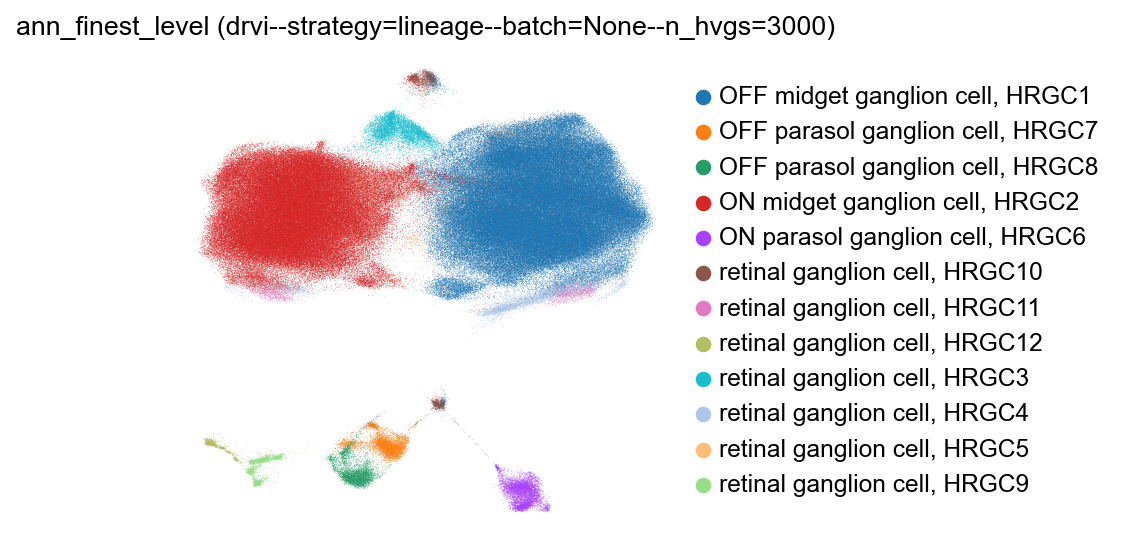

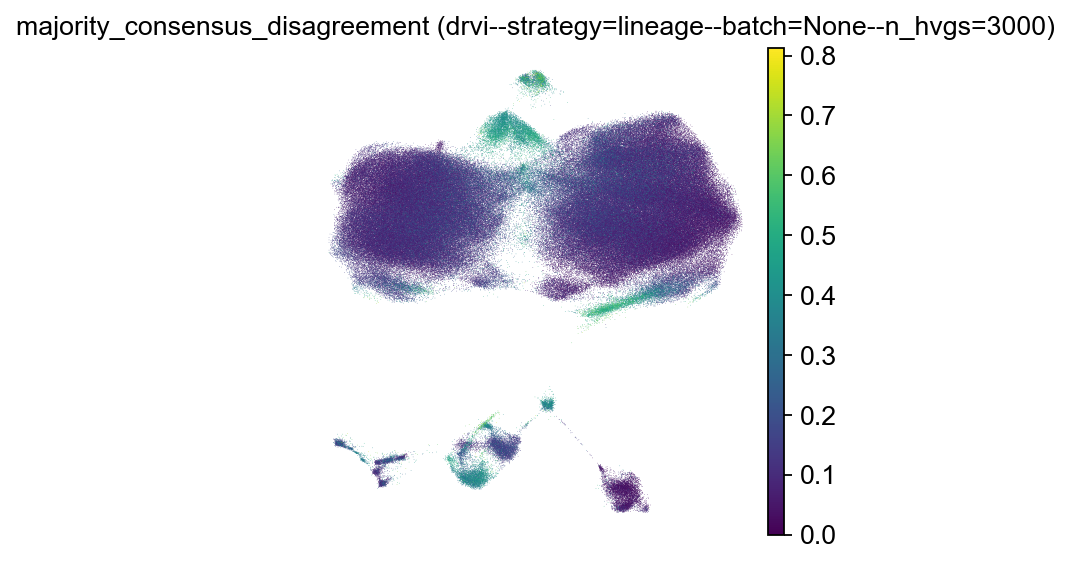

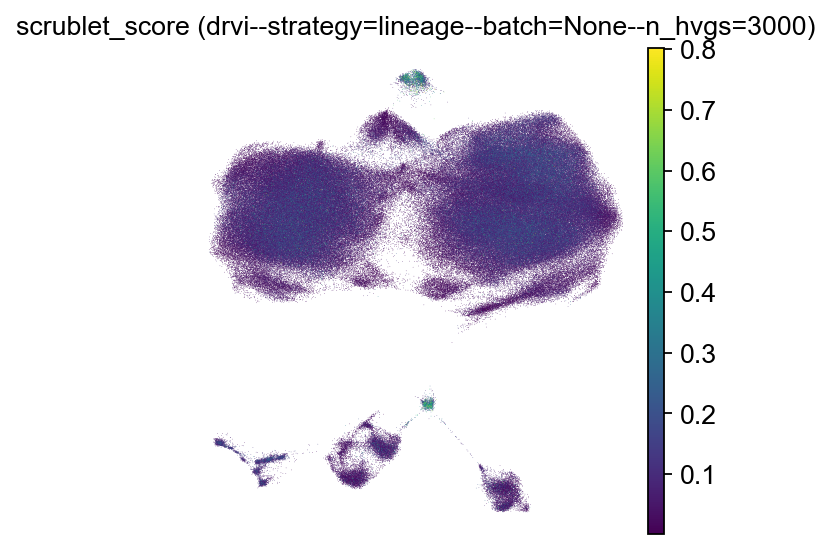

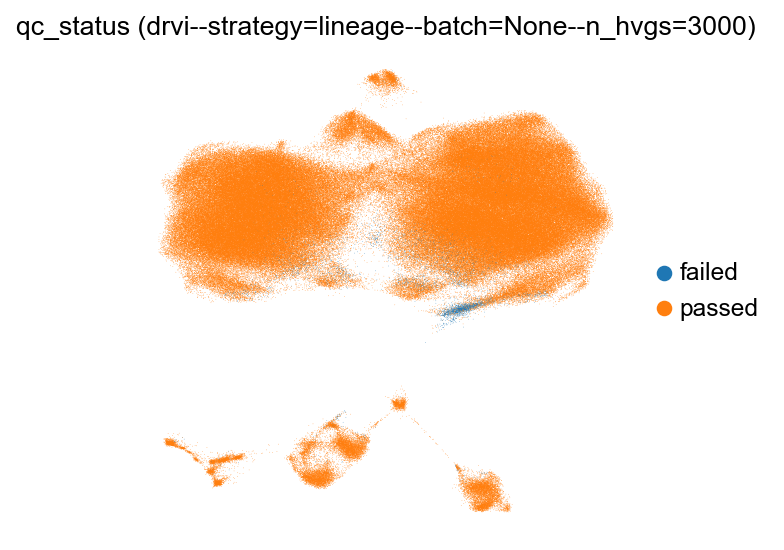

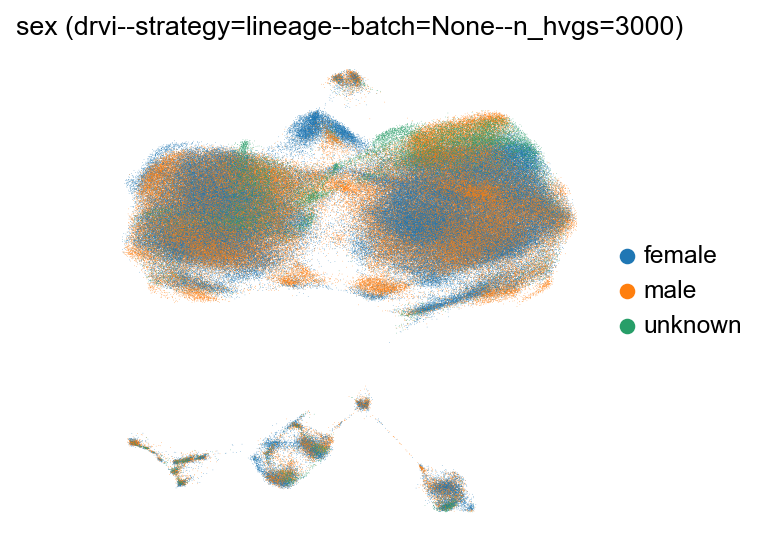

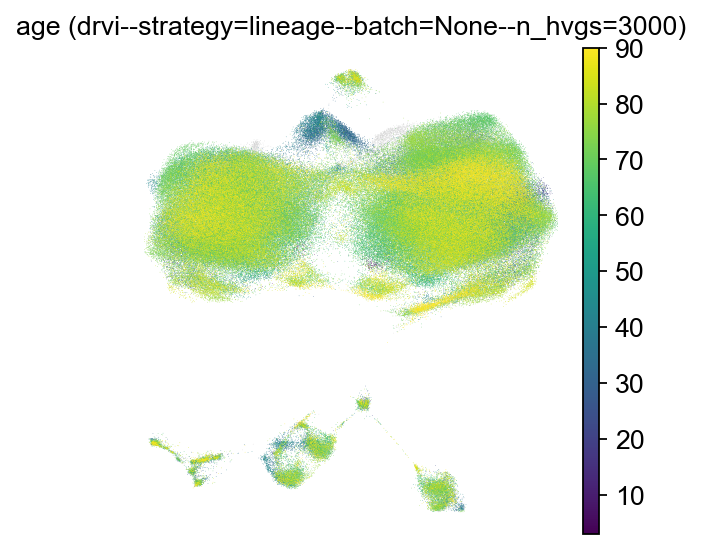

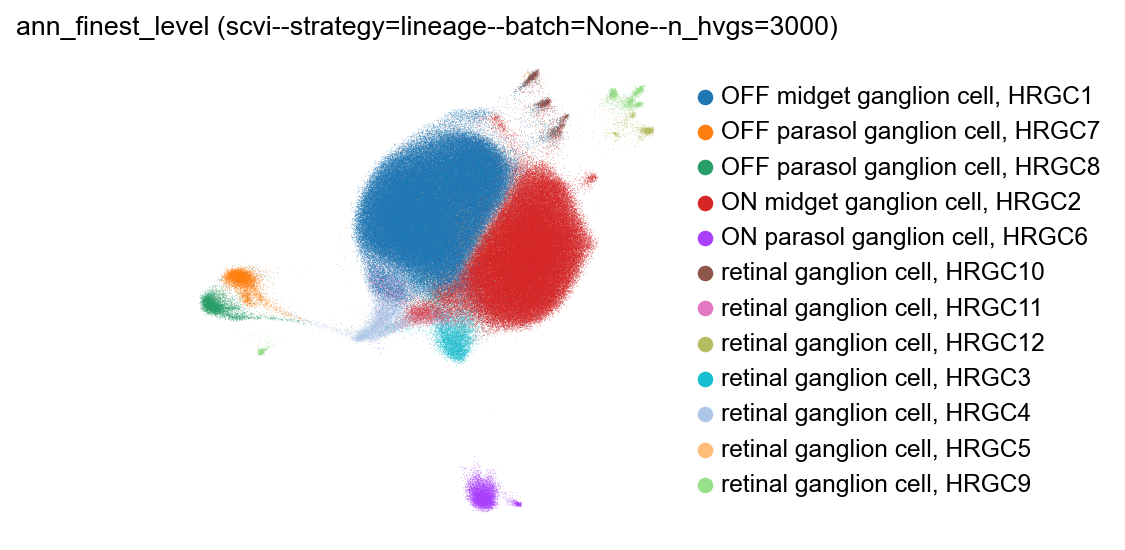

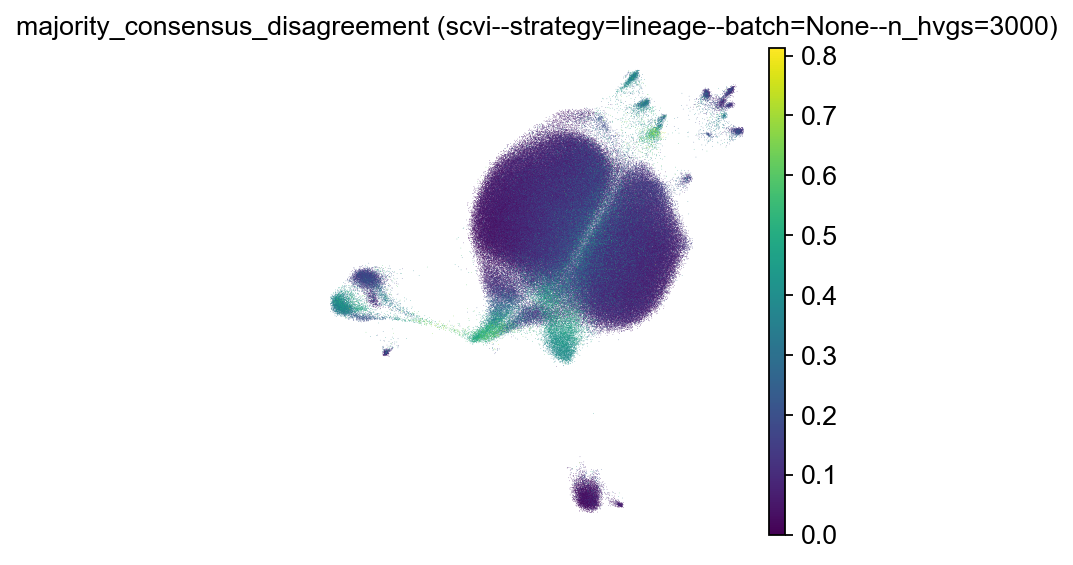

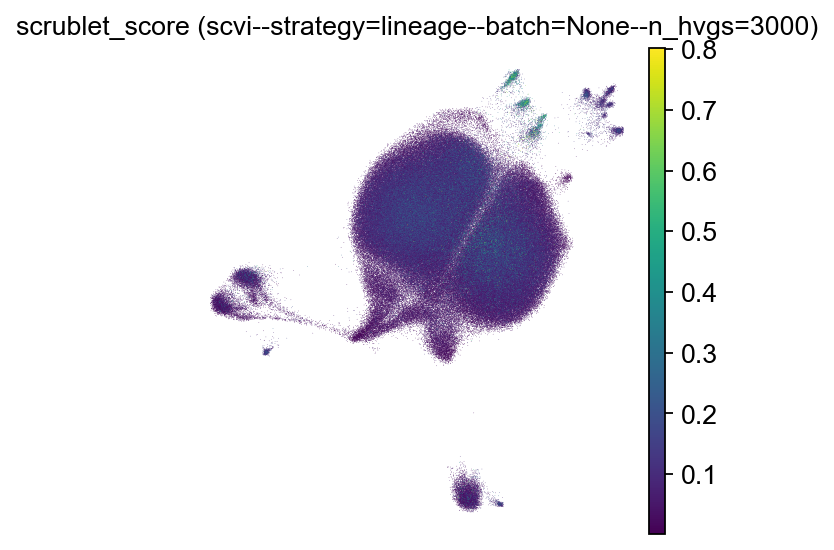

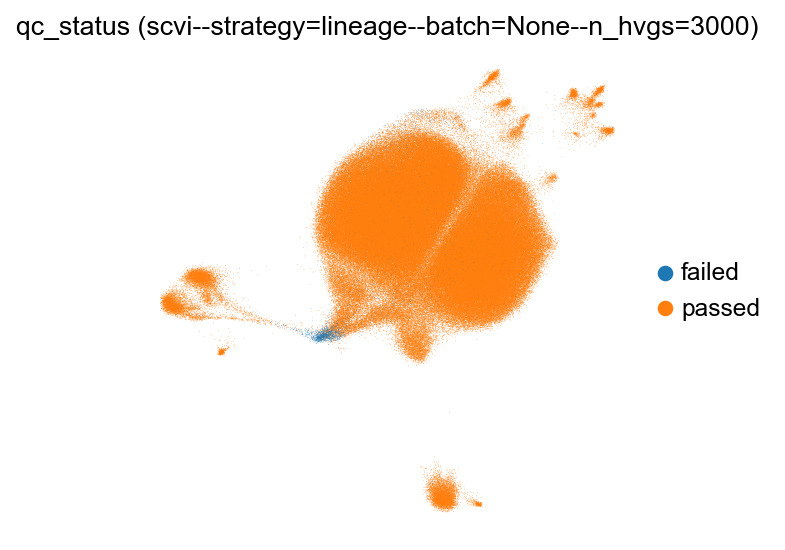

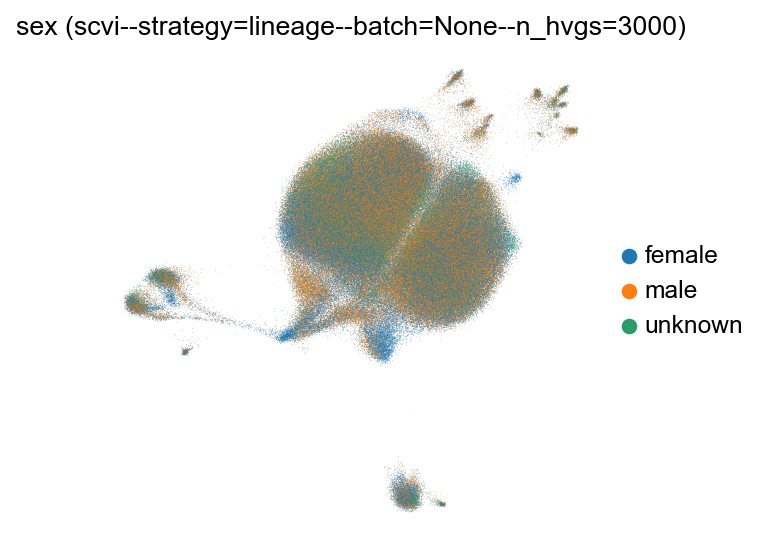

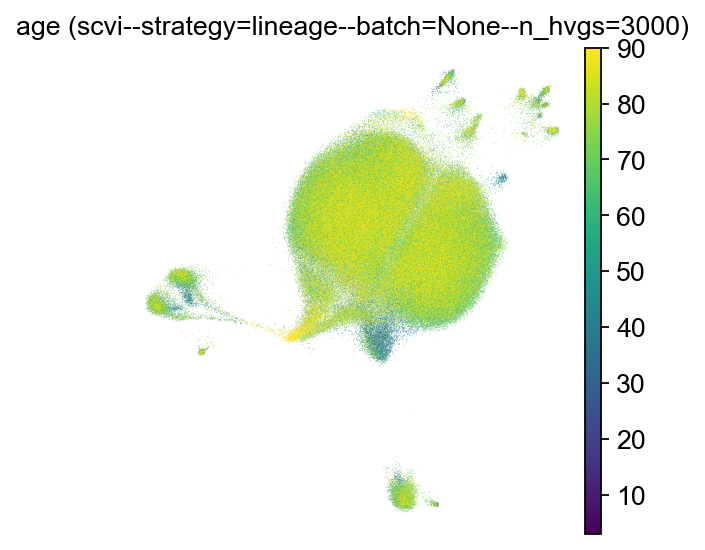

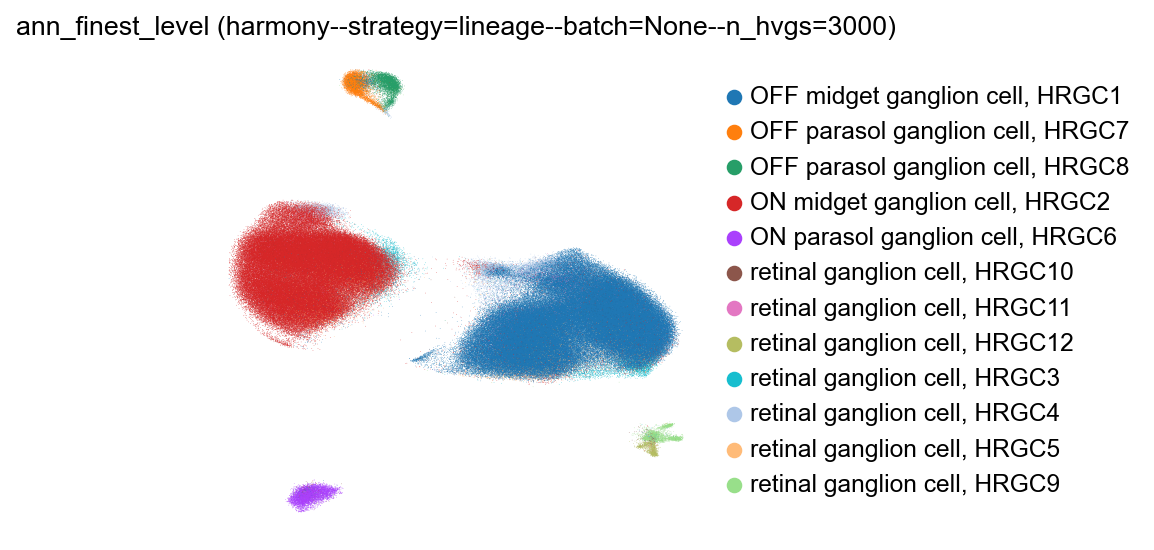

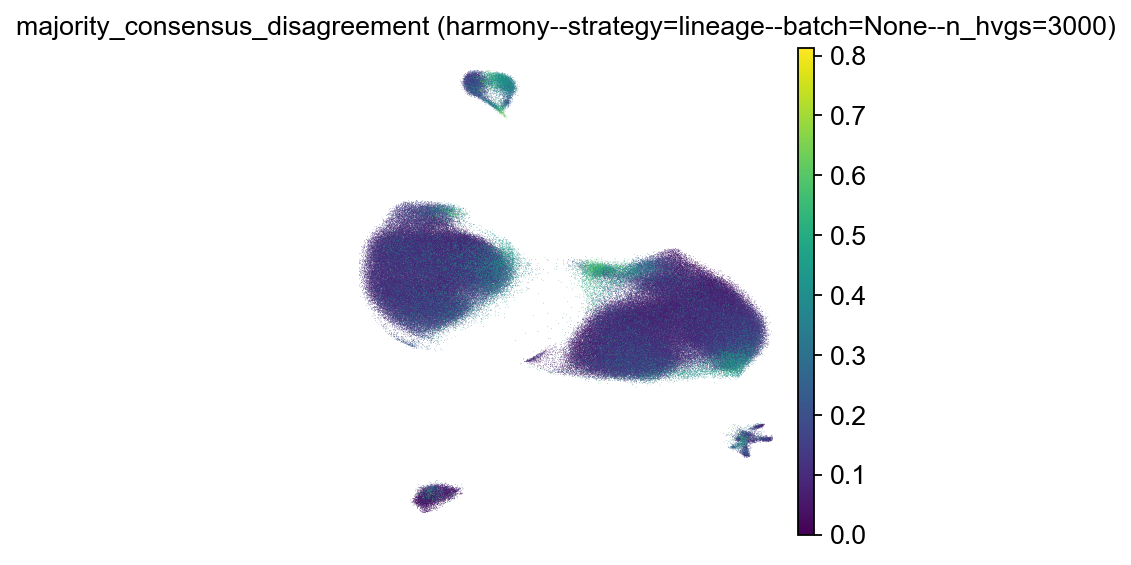

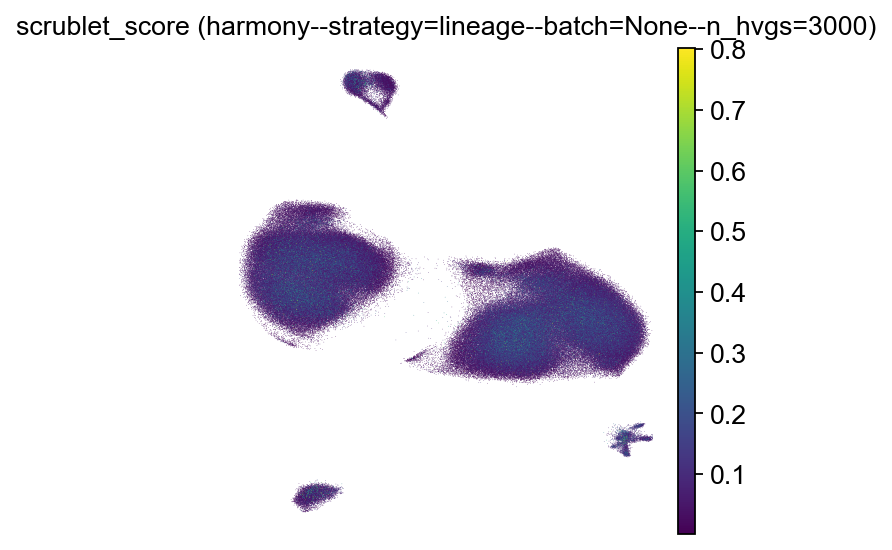

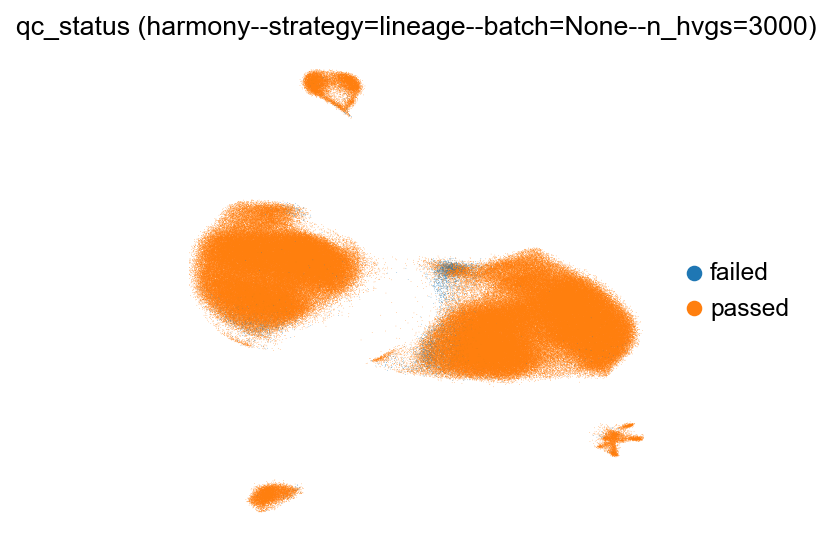

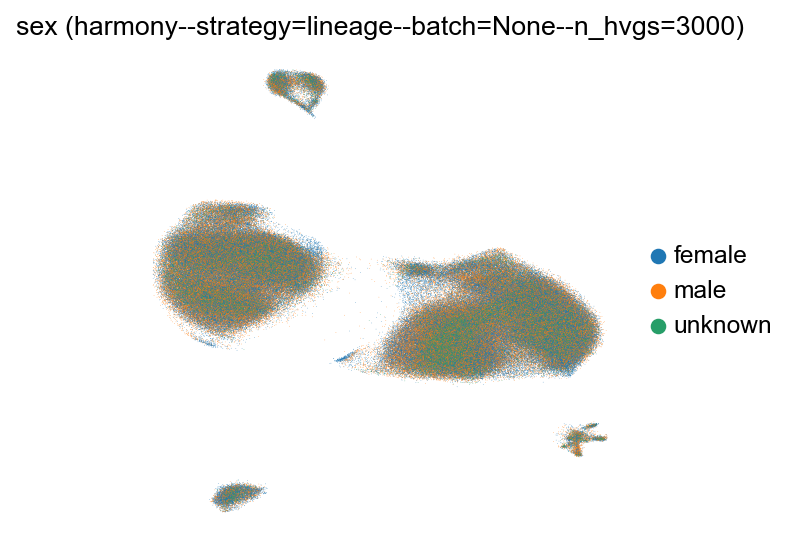

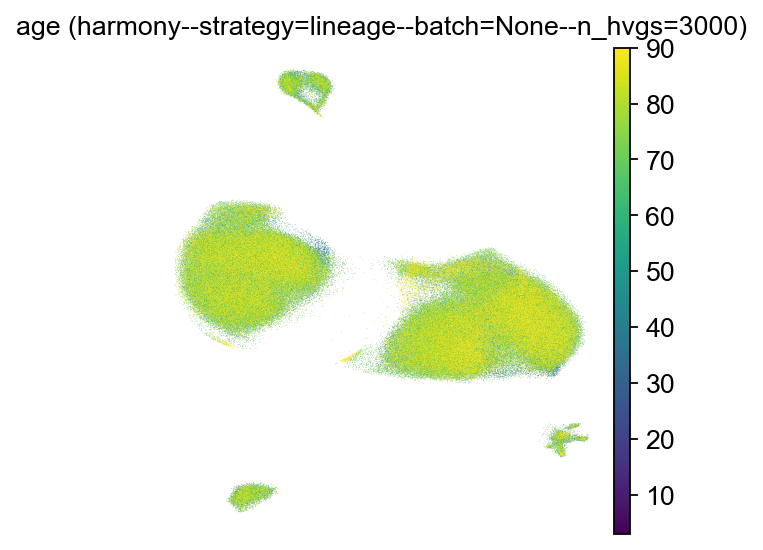

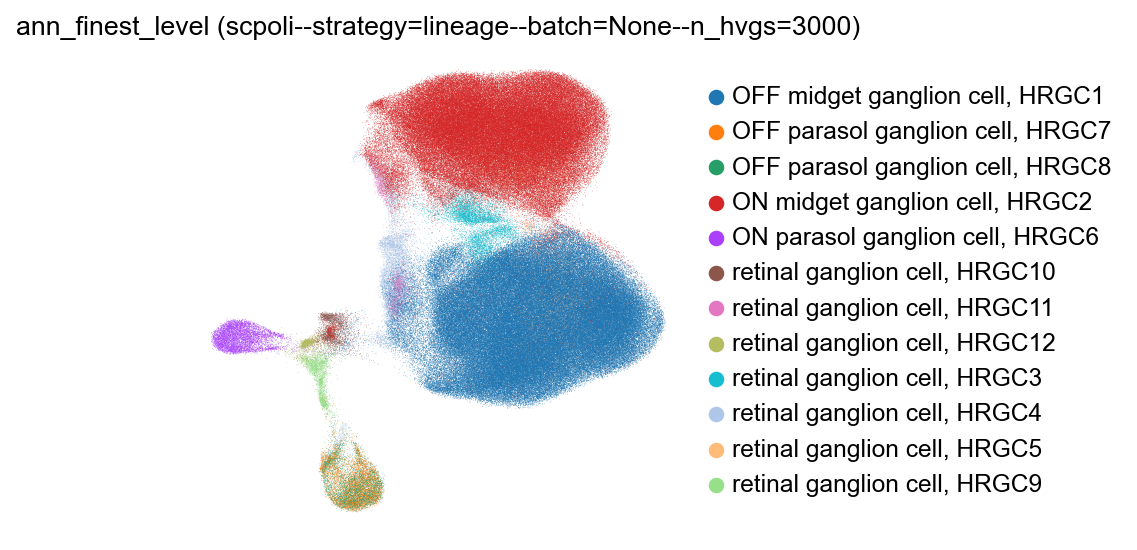

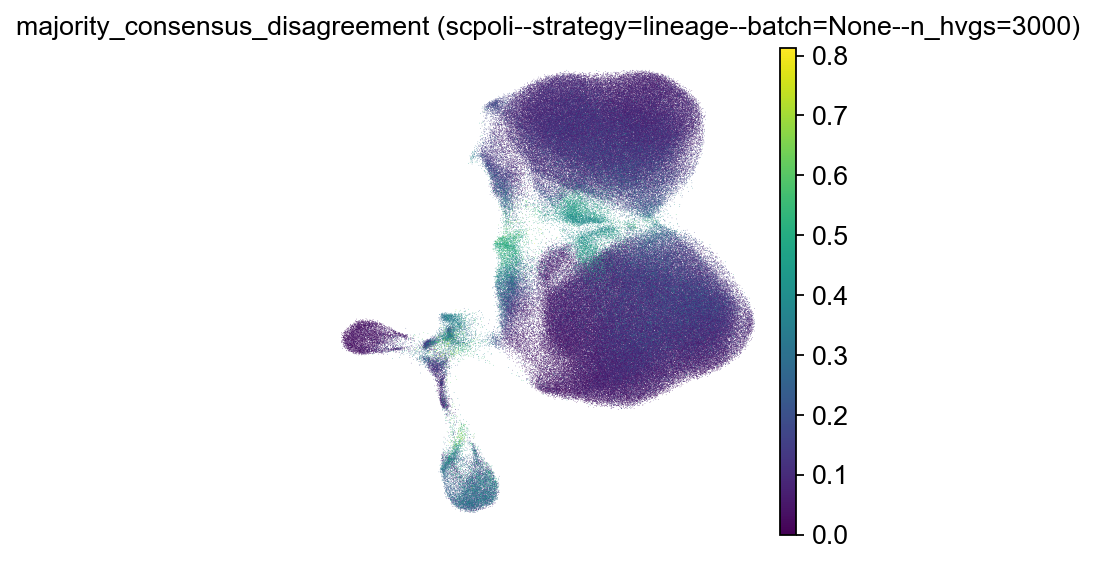

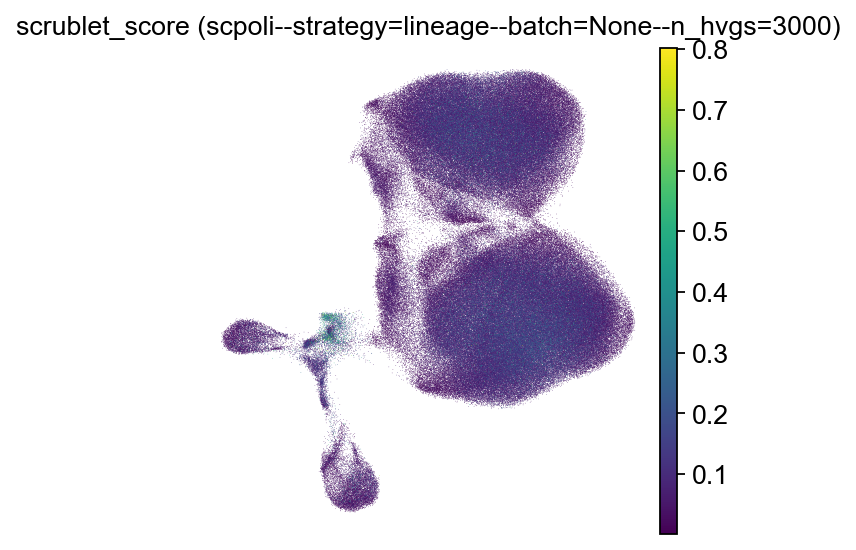

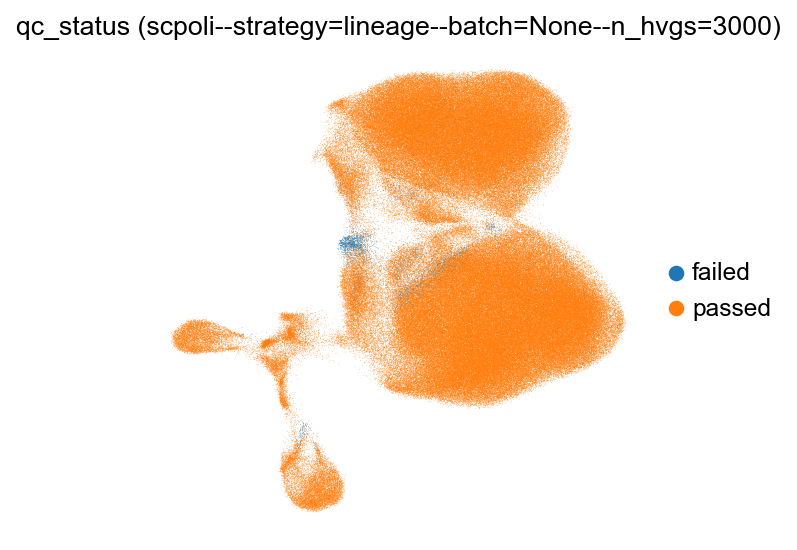

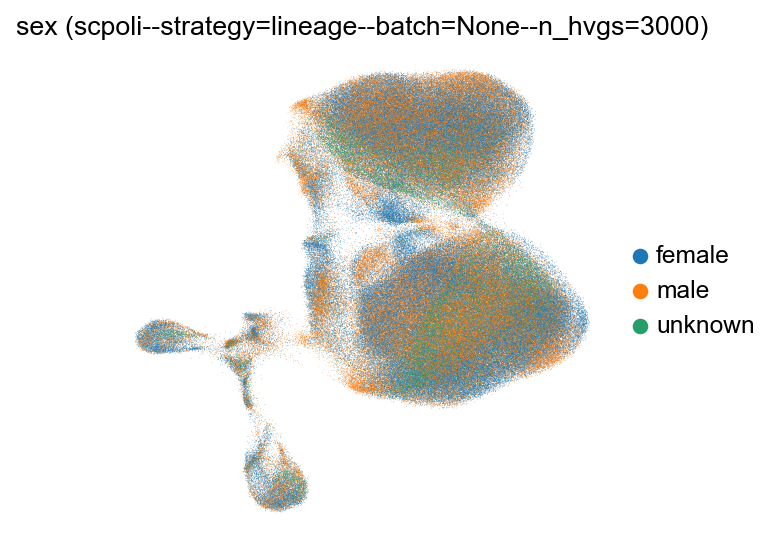

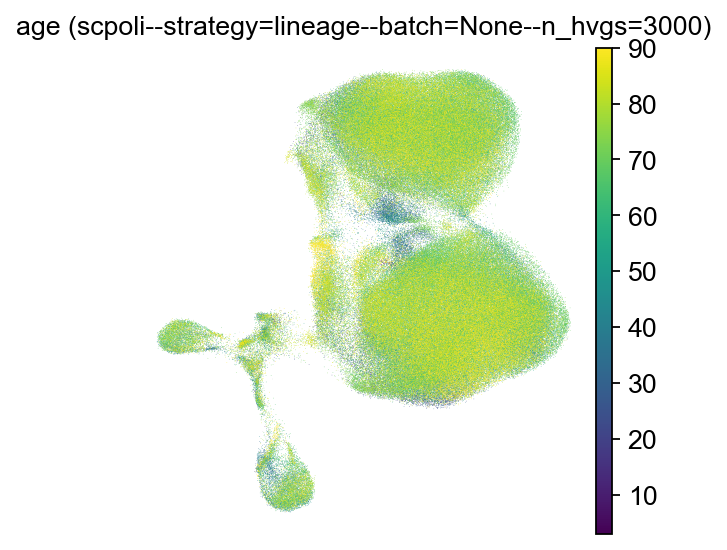

In [22]:
for integration in integrations:
    for color in colors:
        sc.pl.embedding(
            adata,
            basis=f'X_umap--{integration}',
            color=color,
            title=f'{color} ({integration})',
        )

In [17]:
metrics_df = pd.concat(
    adata.uns[key]
    for key in adata.uns.keys()
    if key.startswith('metrics--')
)

In [18]:
metrics_df

,metric,metric_type,batch,label,file_id,dataset,integration_batch,integration_hyperparams,integration_label,integration_method,...,max_vms,max_uss,max_pss,io_in,io_out,mean_load,cpu_time,file_name,strategy,n_hvgs
0,bras_batch,batch_correction,sample_id,ann_finest_level,drvi--strategy=global--batch=None--n_hvgs=1000,RGC,sample_id,4a9ca95bc9,NaN,drvi,...,21202.76,3940.69,3945.70,325.49,3.89,49.20,28.48,drvi,global,1000
1,M's I gs:RGC_midget_off,bio_conservation,sample_id,ann_finest_level,drvi--strategy=global--batch=None--n_hvgs=1000,RGC,sample_id,4a9ca95bc9,NaN,drvi,...,2833.18,1140.46,1140.83,269.15,0.00,19.78,4.08,drvi,global,1000
2,M's I gs:RGC_midget_on,bio_conservation,sample_id,ann_finest_level,drvi--strategy=global--batch=None--n_hvgs=1000,RGC,sample_id,4a9ca95bc9,NaN,drvi,...,2833.18,1140.46,1140.83,269.15,0.00,19.78,4.08,drvi,global,1000
3,M's I gs:RGC_parasol_off,bio_conservation,sample_id,ann_finest_level,drvi--strategy=global--batch=None--n_hvgs=1000,RGC,sample_id,4a9ca95bc9,NaN,drvi,...,2833.18,1140.46,1140.83,269.15,0.00,19.78,4.08,drvi,global,1000
4,M's I gs:RGC_parasol_on,bio_conservation,sample_id,ann_finest_level,drvi--strategy=global--batch=None--n_hvgs=1000,RGC,sample_id,4a9ca95bc9,NaN,drvi,...,2833.18,1140.46,1140.83,269.15,0.00,19.78,4.08,drvi,global,1000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,M's I gs:RGC_photosensitive,bio_conservation,sample_id,ann_finest_level,scvi--strategy=lineage--batch=sample_id--n_hvg...,RGC,sample_id,37055b39e0,NaN,scvi,...,3225.66,1750.09,1752.86,474.17,0.00,45.51,6.42,scvi,lineage,3000
6,M's I:sex,bio_conservation,sample_id,ann_finest_level,scvi--strategy=lineage--batch=sample_id--n_hvg...,RGC,sample_id,37055b39e0,NaN,scvi,...,3225.66,1750.09,1752.86,474.17,0.00,45.51,6.42,scvi,lineage,3000
7,M's I:age,bio_conservation,sample_id,ann_finest_level,scvi--strategy=lineage--batch=sample_id--n_hvg...,RGC,sample_id,37055b39e0,NaN,scvi,...,3225.66,1750.09,1752.86,474.17,0.00,45.51,6.42,scvi,lineage,3000
8,PCreg comp,batch_correction,sample_id,ann_finest_level,scvi--strategy=lineage--batch=sample_id--n_hvg...,RGC,sample_id,37055b39e0,NaN,scvi,...,3225.66,1750.09,1752.86,474.17,0.00,45.51,6.42,scvi,lineage,3000


In [ ]:
metrics_df[['integration_method', 'strategy']] = metrics_df['file_id'].str.split('_', expand=True)

In [ ]:
metrics_df['metric'].unique()

In [ ]:
sns.catplot(
    metrics_df.query('metric == "M\'s I gs:BC_TF"'),
    y='score',
    x='strategy',
    hue='integration_method',
    palette='turbo'
)

In [ ]:
sns.catplot(
    metrics_df.query('metric == "M\'s I gs:BB"'),
    y='score',
    x='strategy',
    hue='integration_method',
    palette='turbo'
)

In [ ]:
sns.catplot(
    metrics_df.query('metric == "M\'s I gs:GB"'),
    y='score',
    x='strategy',
    hue='integration_method',
    palette='turbo'
)